In [1]:
!pip install numpy matplotlib pillow scipy scikit-image opencv-python

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

from PIL import Image
from scipy.signal import wiener
from scipy.ndimage import median_filter
from skimage.feature import local_binary_pattern
from google.colab import files
import io

Saving let.webp to let.webp


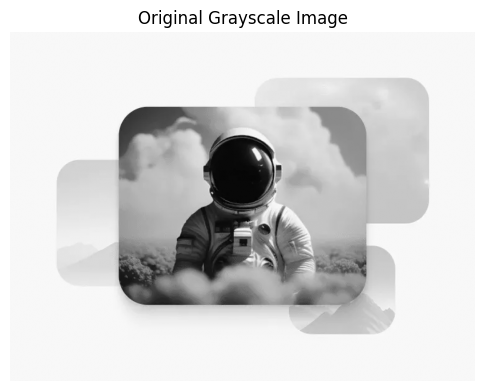

Image uploaded successfully!
Image dimensions: (563, 750)


In [3]:
uploaded = files.upload()

image_name = next(iter(uploaded))

img = Image.open(io.BytesIO(uploaded[image_name])).convert('L')
img = np.array(img, dtype=np.float32) / 255.0

plt.figure(figsize=(6, 5))
plt.imshow(img, cmap='gray')
plt.title("Original Grayscale Image")
plt.axis('off')
plt.show()

print("Image uploaded successfully!")
print("Image dimensions:", img.shape)

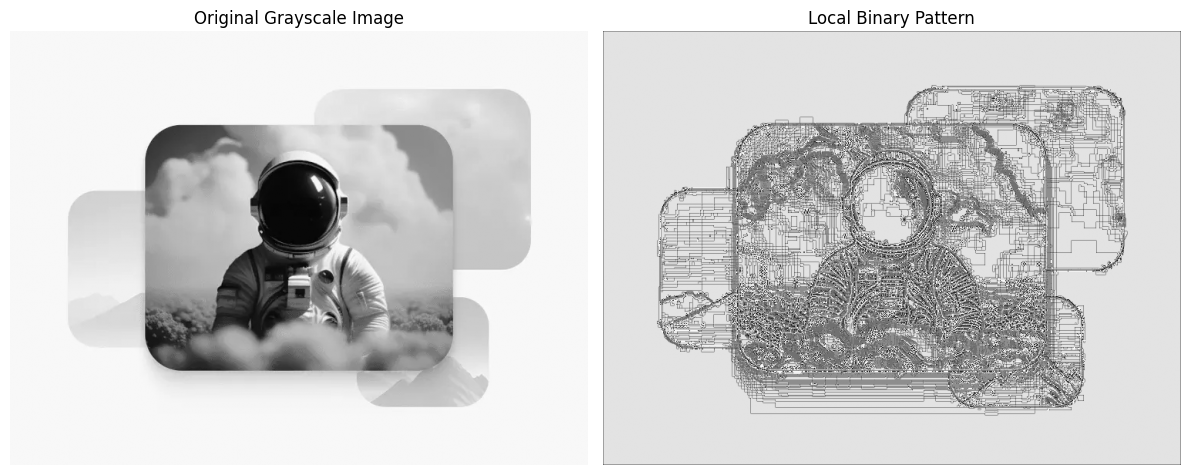

In [4]:
# LBP parameters
P = 8
R = 1

# Convert image to uint8
gray = (img * 255).astype(np.uint8)

# Calculate Local Binary Pattern
lbp = local_binary_pattern(gray, P, R, method='uniform')

# Display original and LBP image
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap='gray')
plt.title("Original Grayscale Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(lbp, cmap='gray')
plt.title("Local Binary Pattern")
plt.axis('off')

plt.tight_layout()
plt.show()

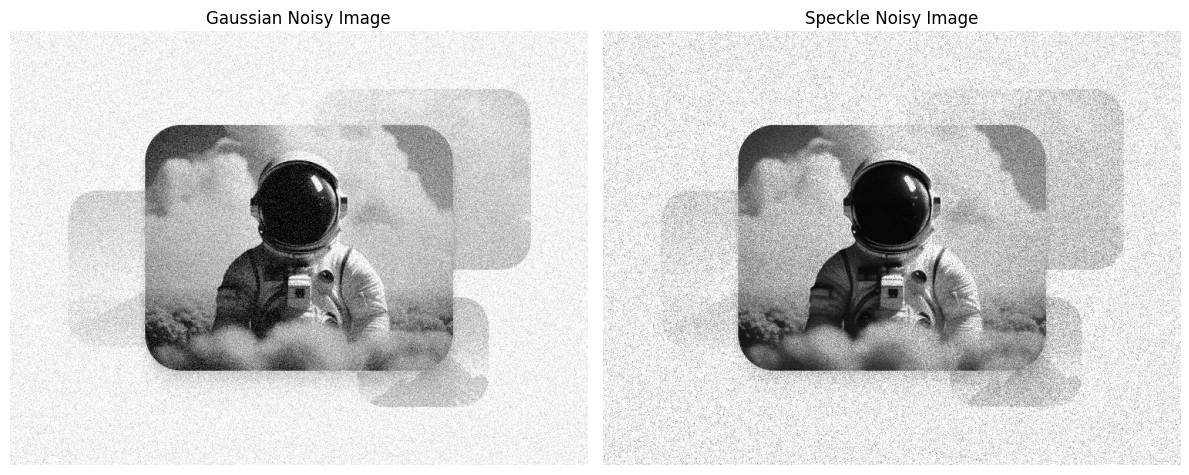

In [5]:
np.random.seed(42)

# Gaussian noise
gaussian_noise = np.random.normal(0, 0.08, img.shape)
gaussian_img = np.clip(img + gaussian_noise, 0, 1)

# Speckle noise
speckle_noise = np.random.normal(0, 0.15, img.shape)
speckle_img = np.clip(img + img * speckle_noise, 0, 1)

# Display noisy images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gaussian_img, cmap='gray')
plt.title("Gaussian Noisy Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(speckle_img, cmap='gray')
plt.title("Speckle Noisy Image")
plt.axis('off')

plt.tight_layout()
plt.show()

In [6]:
# Function to apply all four filters
def apply_filters(noisy_img):

    # 1. Wiener Filter
    wiener_img = wiener(noisy_img, mysize=(5, 5))
    wiener_img = np.clip(wiener_img, 0, 1)

    # Convert image to uint8 for OpenCV filters
    noisy_uint8 = (np.clip(noisy_img, 0, 1) * 255).astype(np.uint8)

    # 2. Median Filter
    median_img = median_filter(noisy_img, size=5)

    # 3. Gaussian Filter
    gaussian_filtered = cv2.GaussianBlur(
        noisy_uint8, (5, 5), 0
    ) / 255.0

    # 4. Bilateral Filter
    bilateral_img = cv2.bilateralFilter(
        noisy_uint8, 5, 50, 50
    ) / 255.0

    return {
        "Wiener Filter": wiener_img,
        "Median Filter": median_img,
        "Gaussian Filter": gaussian_filtered,
        "Bilateral Filter": bilateral_img
    }


# Apply filters to both noisy images
gaussian_results = apply_filters(gaussian_img)
speckle_results = apply_filters(speckle_img)

print("All four filters applied successfully!")

All four filters applied successfully!


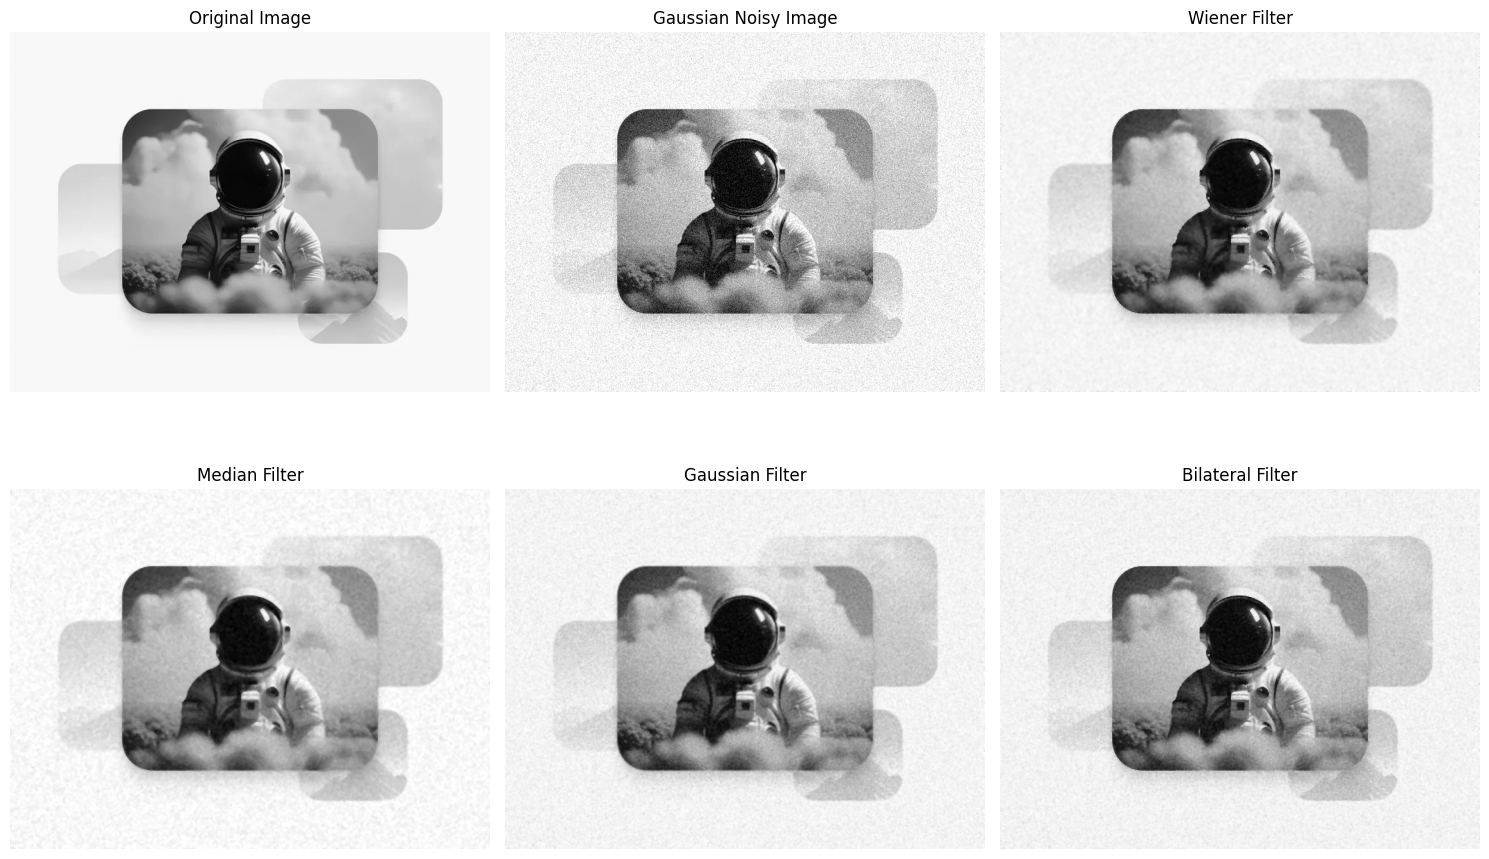

In [7]:
plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(gaussian_img, cmap='gray')
plt.title("Gaussian Noisy Image")
plt.axis('off')

for i, (name, result) in enumerate(gaussian_results.items()):
    plt.subplot(2, 3, i + 3)
    plt.imshow(result, cmap='gray')
    plt.title(name)
    plt.axis('off')

plt.tight_layout()
plt.show()

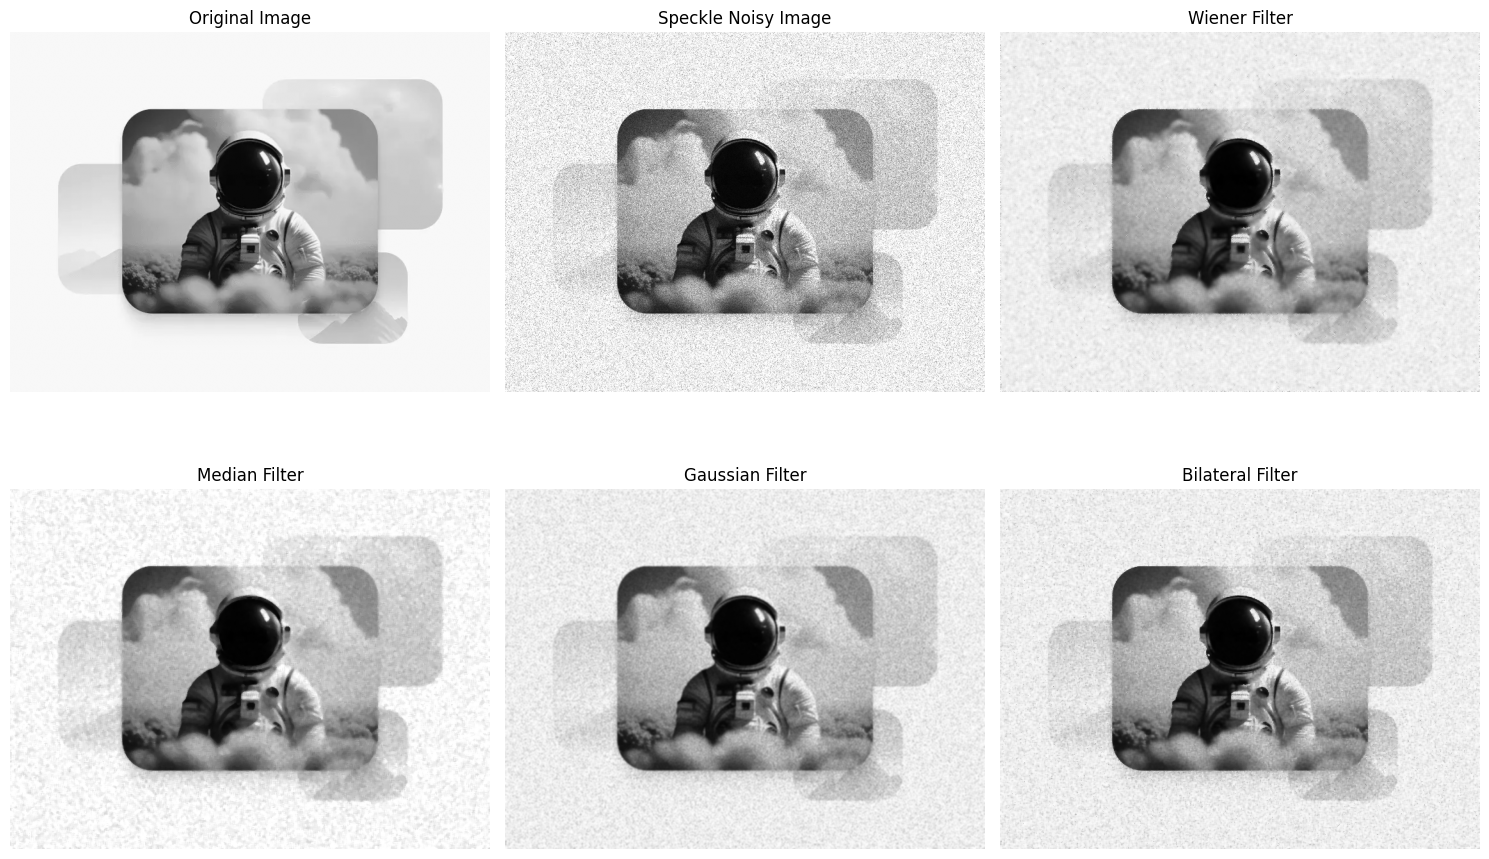

In [8]:
plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(speckle_img, cmap='gray')
plt.title("Speckle Noisy Image")
plt.axis('off')

for i, (name, result) in enumerate(speckle_results.items()):
    plt.subplot(2, 3, i + 3)
    plt.imshow(result, cmap='gray')
    plt.title(name)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [9]:
def calculate_psnr(original, denoised):
    mse = np.mean((original - denoised) ** 2)

    if mse == 0:
        return float('inf')

    return 10 * np.log10(1 / mse)


print("GAUSSIAN NOISE RESULTS")
print("-" * 40)

for name, result in gaussian_results.items():
    print(name, ":", round(calculate_psnr(img, result), 2), "dB")


print("\nSPECKLE NOISE RESULTS")
print("-" * 40)

for name, result in speckle_results.items():
    print(name, ":", round(calculate_psnr(img, result), 2), "dB")

GAUSSIAN NOISE RESULTS
----------------------------------------
Wiener Filter : 31.81 dB
Median Filter : 31.86 dB
Gaussian Filter : 30.97 dB
Bilateral Filter : 30.97 dB

SPECKLE NOISE RESULTS
----------------------------------------
Wiener Filter : 26.98 dB
Median Filter : 29.54 dB
Gaussian Filter : 26.76 dB
Bilateral Filter : 26.06 dB
